# Primary Amoebic Meningoencephalitis (PAM) Clinical Decision Support System
## Phase 1: Project Setup & Data Engineering Pipeline

---

### **Executive Summary & Clinical Rationale**
Primary Amoebic Meningoencephalitis (PAM) is an exceedingly rare, acute, and near-universally fatal central nervous system infection caused by the thermophilic free-living amoeba ***Naegleria fowleri***. 

* **Clinical Challenge:** Symptoms of PAM closely mimic acute bacterial or aseptic viral meningitis—presenting with severe frontal/temporal headache, fever, nausea, and meningismus. However, PAM progresses with fulminant necrotizing encephalitis leading to cerebral edema, herniation, and death typically within **1 to 18 days** (median 5 days from onset).
* **Diagnostic Imperative:** Timely identification is hindered by the extreme rarity of the disease. Standard antimicrobial regimens for meningitis are ineffective against amoebae; survival requires aggressive, specialized early intervention (e.g., intravenous and intrathecal miltefosine, liposomal amphotericin B, rifampin, and targeted temperature management).
* **Machine Learning Objective:** In this Phase 1 foundation, we architect a robust Clinical Data Engineering and Preprocessing Pipeline that integrates clinical presentation, exposure history, and cerebrospinal fluid (CSF) biomarkers, resolves extreme class rarity via algorithmic oversampling, and establishes reproducible MLOps artifacts.

---

### **Phase 1 Pipeline Architecture**
```
pam_ai_ops_project/
├── data/
│   ├── raw/
│   │   └── synthetic_pam_raw_1000.csv       <- Raw cohort (1000, 14)
│   └── processed/
│       ├── X_train.csv                      <- Training features (1312, 13)
│       ├── X_test.csv                       <- Testing features (328, 13)
│       ├── y_train.csv                      <- Training labels (1312, 1)
│       └── y_test.csv                       <- Testing labels (328, 1)
├── models/
│   └── artifacts/
│       └── scaler.pkl                       <- Persisted MinMaxScaler
├── notebooks/
│   └── 01_phase1_data_engineering.ipynb     <- This interactive notebook
├── src/
│   ├── __init__.py
│   ├── generate_data.py                     <- Synthetic cohort generator
│   └── preprocess.py                        <- Modular preprocessing pipeline
└── requirements.txt                         <- Pinned dependencies
```

In [1]:
import sys
from pathlib import Path

# Configure project root relative paths
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "pam_ai_ops_project" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set publication plotting standards
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120

print(f"Project root resolved to: {PROJECT_ROOT}")
print("Dependencies and plotting environment successfully initialized.")

Project root resolved to: C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project
Dependencies and plotting environment successfully initialized.


## Step 2: Synthetic Clinical Cohort Generation

### **Biomarker & Clinical Feature Schema**
To model early PAM presentation while accurately reflecting clinical epidemiology, 14 features are engineered:

| Feature Category | Variable Name | Type | Clinical Description & Diagnostic Value |
| :--- | :--- | :--- | :--- |
| **Exposure History** | `Freshwater_Exposure` | Binary (0/1) | Primary entry route (warm freshwater lakes, rivers, hot springs). Skewed to 1 in PAM. |
| **Exposure History** | `Nasal_Irrigation_History` | Binary (0/1) | Sinus irrigation or ritual ablution using unboiled tap water (known infection vector). |
| **Meningeal Signs** | `Severe_Headache` | Binary (0/1) | Intense frontal/bitemporal headache caused by olfactory/frontal lobe necrosis. |
| **Systemic Sign** | `Fever` | Binary (0/1) | High pyrexia reflecting severe inflammatory response. |
| **Neurological Sign** | `Nausea_Vomiting` | Binary (0/1) | Cardinal sign of elevated intracranial pressure (ICP). |
| **Meningeal Signs** | `Stiff_Neck` | Binary (0/1) | Classic nuchal rigidity / meningismus from meningeal inflammation. |
| **Encephalitic Sign** | `Confusion` | Binary (0/1) | Progressive altered mental status and delirium as amoebae destroy parenchyma. |
| **Neurological Sign** | `Seizures` | Binary (0/1) | Cortical irritation and acute necrotizing lesions. |
| **Meningeal Signs** | `Photophobia` | Binary (0/1) | Heightened light sensitivity characteristic of meningeal irritation. |
| **Demographics** | `Age` | Numeric [1, 80] | Skewed towards active children/young adults engaged in water sports (mean ~23). |
| **Clinical Timing** | `Symptom_Onset_Days` | Numeric [1, 12] | Days since initial symptom onset; PAM has hyper-acute presentation (mean ~3.8 days). |
| **CSF Biomarker** | `CSF_Pressure` | Numeric | Lumbar puncture opening pressure (mmH2O); markedly elevated in PAM (mean ~385). |
| **CSF Biomarker** | `CSF_WBC_Count` | Numeric | Pleocytosis (cells/mm3) with prominent neutrophilic shift (mean ~600 in PAM). |
| **Ground Truth** | `Target` | Binary (0/1) | 1 = Confirmed PAM, 0 = Non-PAM Acute Meningitis Control. |

The raw cohort contains **1,000 synthetic clinical records** (820 negative controls, 180 positive PAM cases) generated with fixed seed `np.random.seed(42)`.

In [2]:
from src.generate_data import generate_pam_synthetic_data

raw_csv_path = PROJECT_ROOT / "data" / "raw" / "synthetic_pam_raw_1000.csv"

# Execute data generation
df_raw = generate_pam_synthetic_data(
    n_neg=820,
    n_pos=180,
    random_state=42,
    output_path=raw_csv_path,
)

print(f"Raw cohort successfully generated and verified.")
print(f"Shape: {df_raw.shape}")
print(f"Class Breakdown: {df_raw['Target'].value_counts().to_dict()}")
df_raw.head()

Dataset successfully saved to: C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project\data\raw\synthetic_pam_raw_1000.csv
Raw cohort successfully generated and verified.
Shape: (1000, 14)
Class Breakdown: {0: 820, 1: 180}


,Freshwater_Exposure,Nasal_Irrigation_History,Severe_Headache,Fever,Nausea_Vomiting,Stiff_Neck,Confusion,Seizures,Photophobia,Age,Symptom_Onset_Days,CSF_Pressure,CSF_WBC_Count,Target
0,0,0,1,0,1,0,0,0,1,41,4,120.0,203.4,1
1,0,0,1,1,1,0,1,0,0,17,10,214.9,106.0,0
2,0,0,1,1,0,1,0,0,0,54,7,257.2,141.2,0
3,0,0,1,0,1,0,0,0,1,38,4,171.9,171.4,0
4,1,0,0,1,0,0,0,0,0,31,3,205.4,156.6,0


### **Exploratory Biomarker Inspection**
Let us inspect the distinct clinical separating power of cerebrospinal fluid (CSF) opening pressure and white blood cell (WBC) pleocytosis between the PAM positive group and negative control patients.

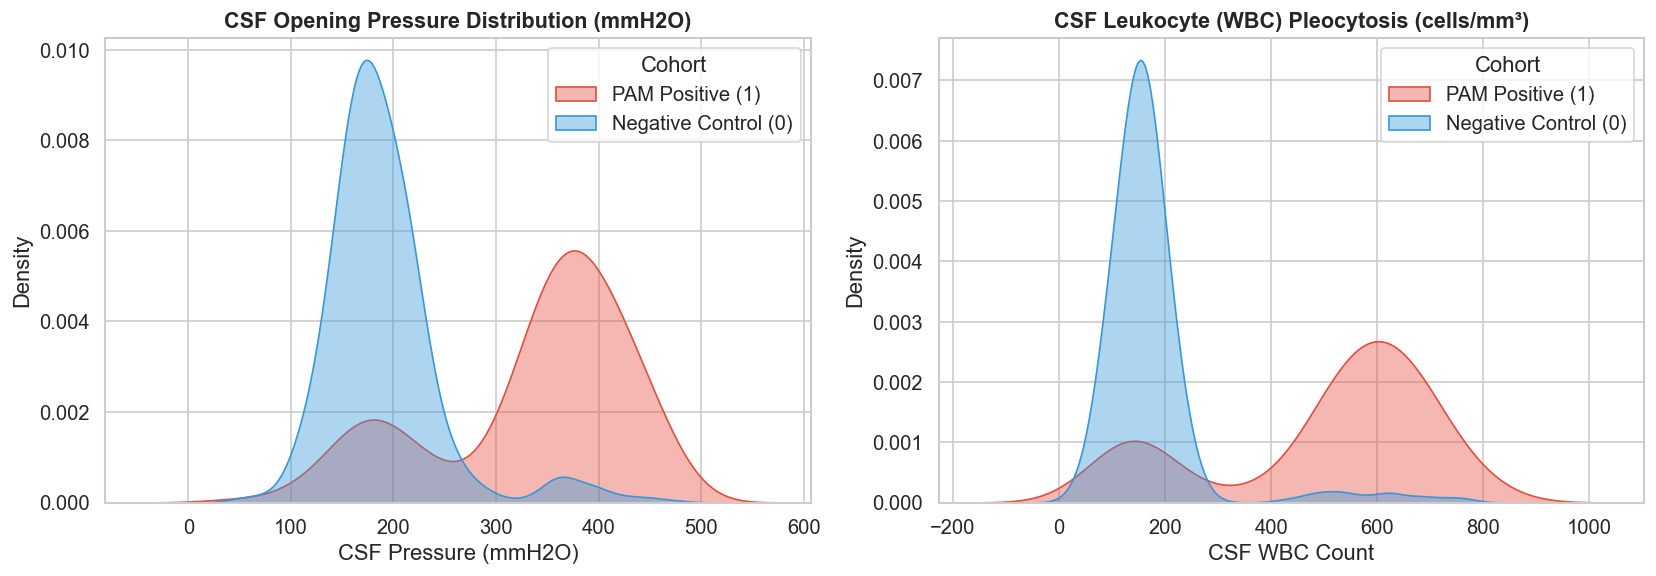

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# CSF Opening Pressure Distribution
sns.kdeplot(
    data=df_raw,
    x="CSF_Pressure",
    hue="Target",
    common_norm=False,
    fill=True,
    palette=["#3498db", "#e74c3c"],
    alpha=0.4,
    ax=axes[0],
)
axes[0].set_title("CSF Opening Pressure Distribution (mmH2O)", fontsize=13, weight="bold")
axes[0].set_xlabel("CSF Pressure (mmH2O)")
axes[0].legend(title="Cohort", labels=["PAM Positive (1)", "Negative Control (0)"])

# CSF WBC Count Distribution
sns.kdeplot(
    data=df_raw,
    x="CSF_WBC_Count",
    hue="Target",
    common_norm=False,
    fill=True,
    palette=["#3498db", "#e74c3c"],
    alpha=0.4,
    ax=axes[1],
)
axes[1].set_title("CSF Leukocyte (WBC) Pleocytosis (cells/mm³)", fontsize=13, weight="bold")
axes[1].set_xlabel("CSF WBC Count")
axes[1].legend(title="Cohort", labels=["PAM Positive (1)", "Negative Control (0)"])

plt.tight_layout()
plt.show()

## Step 3: Preprocessing Pipeline & Clinical Imbalance Mitigation

### **1. Missing Value Imputation Strategy**
* **Numeric Vitals (`Age`, `Symptom_Onset_Days`, `CSF_Pressure`, `CSF_WBC_Count`):** Imputed using the **median**. In emergency medicine datasets, physiological vitals often exhibit heavy right-skew or laboratory reporting outliers; the median represents a robust non-parametric central tendency measure.
* **Binary Clinical Features:** Imputed using the **mode**. Preserves discrete clinical boolean flags ({0, 1}) without introducing fractional states.

---

### **2. Min-Max Normalization**
Continuous variables have disparate physical scales (e.g., CSF WBC count reaches ~900 cells/mm³, whereas symptom onset days spans 1–12). Distance-based learning algorithms and oversampling manifolds can be unduly dominated by higher-magnitude dimensions. 
$$\tilde{x} = \frac{x - x_{\min}}{x_{\max} - x_{\min}} \in [0, 1]$$
The fitted `MinMaxScaler` is persisted to `models/artifacts/scaler.pkl` using `joblib` for reproducible deployment in production inference.

---

### **3. Why We Use SMOTE for Rare Clinical Diseases**
* **The Clinical Asymmetry Problem:** In high-fatality conditions like PAM (>97% mortality), a **false negative (missed diagnosis)** is fatal, whereas a **false positive (prompting PCR testing and empirical miltefosine)** is clinically manageable. Standard machine learning classifiers trained on unweighted, imbalanced datasets minimize empirical error by favoring the majority negative class, resulting in unacceptably low clinical sensitivity.
* **Limitations of Random Oversampling:** Naive random duplication of minority samples results in duplicate points in the hypothesis space, leading to decision tree memorization, severe overfitting, and poor out-of-sample generalization.
* **The SMOTE Solution:** Synthetic Minority Over-sampling Technique (Chawla et al., 2002) synthesizes plausible new clinical phenotypes along the line segments connecting minority instances and their $k$-nearest neighbors:
$$\mathbf{x}_{\text{new}} = \mathbf{x}_i + \lambda (\mathbf{x}_{zi} - \mathbf{x}_i), \quad \lambda \sim U(0, 1)$$
SMOTE expands the minority decision boundary, enabling downstream classifiers to learn generalizable decision surfaces for rare presentations. Here, SMOTE balances the 180 positive cases up to **820 cases**, yielding a balanced cohort of **1,640 records**.

---

### **4. Stratified Data Splitting**
An 80/20 train-test split (`train_test_split(stratify=y, random_state=42)`) ensures that train (1,312 records) and test (328 records) subsets preserve identical balanced 1:1 class proportions without distribution shift.

In [4]:
from src.preprocess import preprocess_pam_data

# Execute the complete preprocessing pipeline
X_train, X_test, y_train, y_test, scaler, df_raw_check, df_smote = preprocess_pam_data(
    raw_data_path=raw_csv_path,
    processed_dir=PROJECT_ROOT / "data" / "processed",
    artifacts_dir=PROJECT_ROOT / "models" / "artifacts",
    random_state=42,
)

print("\n" + "=" * 60)
print("PREPROCESSING PIPELINE EXECUTION VERIFICATION:")
print("=" * 60)
print(f"1. Raw Cohort Shape:       {df_raw_check.shape}")
print(f"2. SMOTE Cohort Shape:     {df_smote.shape}")
print(f"3. X_train Feature Shape:  {X_train.shape}")
print(f"4. X_test Feature Shape:   {X_test.shape}")
print(f"5. y_train Label Shape:    {y_train.shape}")
print(f"6. y_test Label Shape:     {y_test.shape}")
print("=" * 60)

Loaded raw cohort from C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project\data\raw\synthetic_pam_raw_1000.csv with shape: (1000, 14)
Saved fitted MinMaxScaler to: C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project\models\artifacts\scaler.pkl
SMOTE cohort shape: (1640, 14)
SMOTE class distribution: {1: 820, 0: 820}
Train features shape: (1312, 13), Test features shape: (328, 13)
Train labels shape: (1312,), Test labels shape: (328,)
Saved processed datasets to: C:\Users\Rohan\Documents\AML Project\pam_ai_ops_project\data\processed
  - X_train.csv
  - X_test.csv
  - y_train.csv
  - y_test.csv

PREPROCESSING PIPELINE EXECUTION VERIFICATION:
1. Raw Cohort Shape:       (1000, 14)
2. SMOTE Cohort Shape:     (1640, 14)
3. X_train Feature Shape:  (1312, 13)
4. X_test Feature Shape:   (328, 13)
5. y_train Label Shape:    (1312,)
6. y_test Label Shape:     (328,)


## Step 4: Class Distribution Comparative Analysis

Below, we visualize the cohort class distribution **before** and **after** SMOTE oversampling to demonstrate the balancing effect.

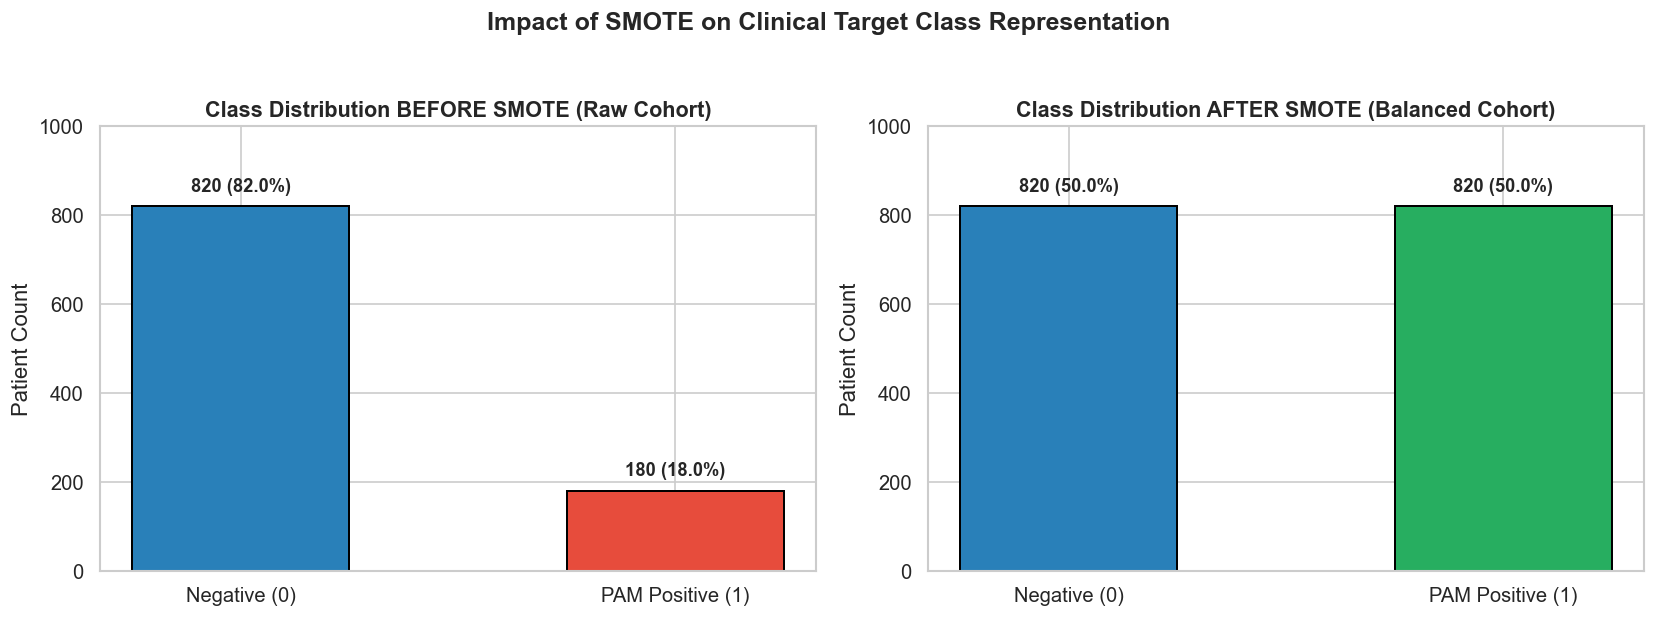

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Cohort Distribution
raw_counts = df_raw_check["Target"].value_counts().sort_index()
raw_bars = axes[0].bar(
    ["Negative (0)", "PAM Positive (1)"],
    raw_counts.values,
    color=["#2980b9", "#e74c3c"],
    width=0.5,
    edgecolor="black",
    linewidth=1.2,
)
axes[0].set_title("Class Distribution BEFORE SMOTE (Raw Cohort)", fontsize=13, weight="bold")
axes[0].set_ylabel("Patient Count")
axes[0].set_ylim(0, 1000)

for bar in raw_bars:
    yval = bar.get_height()
    pct = (yval / len(df_raw_check)) * 100
    axes[0].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 25,
        f"{int(yval):,} ({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=11,
    )

# SMOTE Resampled Cohort Distribution
smote_counts = df_smote["Target"].value_counts().sort_index()
smote_bars = axes[1].bar(
    ["Negative (0)", "PAM Positive (1)"],
    smote_counts.values,
    color=["#2980b9", "#27ae60"],
    width=0.5,
    edgecolor="black",
    linewidth=1.2,
)
axes[1].set_title("Class Distribution AFTER SMOTE (Balanced Cohort)", fontsize=13, weight="bold")
axes[1].set_ylabel("Patient Count")
axes[1].set_ylim(0, 1000)

for bar in smote_bars:
    yval = bar.get_height()
    pct = (yval / len(df_smote)) * 100
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        yval + 25,
        f"{int(yval):,} ({pct:.1f}%)",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=11,
    )

plt.suptitle("Impact of SMOTE on Clinical Target Class Representation", fontsize=15, weight="bold", y=1.03)
plt.tight_layout()
plt.show()

## Phase 1 Artifacts & Verification Summary

All Phase 1 pipeline outputs have been generated and persisted in accordance with the project specifications.

### **Exported Artifacts Inventory**
1. **Raw Dataset:** `data/raw/synthetic_pam_raw_1000.csv`
2. **Normalized Train Features:** `data/processed/X_train.csv` (1312 rows, 13 features)
3. **Normalized Test Features:** `data/processed/X_test.csv` (328 rows, 13 features)
4. **Stratified Train Labels:** `data/processed/y_train.csv` (1312 rows)
5. **Stratified Test Labels:** `data/processed/y_test.csv` (328 rows)
6. **Persisted Scaler:** `models/artifacts/scaler.pkl` (Fitted `MinMaxScaler`)

In [6]:
artifacts = {
    "Raw CSV": PROJECT_ROOT / "data" / "raw" / "synthetic_pam_raw_1000.csv",
    "X_train": PROJECT_ROOT / "data" / "processed" / "X_train.csv",
    "X_test": PROJECT_ROOT / "data" / "processed" / "X_test.csv",
    "y_train": PROJECT_ROOT / "data" / "processed" / "y_train.csv",
    "y_test": PROJECT_ROOT / "data" / "processed" / "y_test.csv",
    "Scaler": PROJECT_ROOT / "models" / "artifacts" / "scaler.pkl",
}

print("=" * 70)
print("FINAL ARTIFACT INTEGRITY CHECK")
print("=" * 70)

for label, p in artifacts.items():
    exists = p.exists()
    size_kb = p.stat().st_size / 1024 if exists else 0
    status = "EXISTS" if exists else "MISSING"
    print(f"{label:12} | {status:8} | Size: {size_kb:7.2f} KB | Path: {p.relative_to(PROJECT_ROOT)}")

# Test loading the persisted scaler
loaded_scaler = joblib.load(artifacts["Scaler"])
print("\nSuccessfully reloaded fitted scaler from disk:")
print(f"Scaler type: {type(loaded_scaler)}")
print(f"Feature ranges: {loaded_scaler.data_range_}")
print("=" * 70)
print("Phase 1 Project Setup & Data Engineering successfully complete!")

FINAL ARTIFACT INTEGRITY CHECK
Raw CSV      | EXISTS   | Size:   37.17 KB | Path: data\raw\synthetic_pam_raw_1000.csv
X_train      | EXISTS   | Size:  122.02 KB | Path: data\processed\X_train.csv
X_test       | EXISTS   | Size:   30.61 KB | Path: data\processed\X_test.csv
y_train      | EXISTS   | Size:    3.85 KB | Path: data\processed\y_train.csv
y_test       | EXISTS   | Size:    0.97 KB | Path: data\processed\y_test.csv
Scaler       | EXISTS   | Size:    1.10 KB | Path: models\artifacts\scaler.pkl

Successfully reloaded fitted scaler from disk:
Scaler type: <class 'sklearn.preprocessing._data.MinMaxScaler'>
Feature ranges: [ 79.   11.  429.6 805.7]
Phase 1 Project Setup & Data Engineering successfully complete!
